In [36]:
%load_ext autoreload
%autoreload 2

import numpy as np
import matplotlib.pyplot as plt
import utils as ut

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


# Introducion

Here we train one model and observe convergence, similar to `logistic_regression/introduction.ipynb`.

# Parameters

In [ ]:
# HYPERPARAMETERS

learning_rate = 0.05
epochs = 5000
lam = 0

data = "5000_100_50"

In [ ]:
# load and prepare data
dataset = np.load(f"{data}.npz")

X = dataset["X"]
y = dataset["y"]
T = float(dataset["T"])
alpha_over_J = float(dataset["alpha_over_J"])

X_train = X[:60000]
X_test = X[60000:]

y_train = y[:60000]
y_test = y[60000:]

X_train, X_test = ut.normalise(X_train, X_test)

# checks
print(X_train.shape, X_test.shape)
print(f"T = {T}")
print(f"alpha/J = {alpha_over_J}")
print("")

print("NaN values:", np.isnan(X_train).any())
print("Infinite values:", np.isinf(X_train).any())
print("")

print("Maximum absolute value:", np.max(np.abs(X_train)))
print("Mean absolute value:", np.mean(np.abs(X_train)))

(60000, 784) (10000, 784)
T = 2.0
alpha/J = 1.0

NaN values: False
Infinite values: False

Maximum absolute value: 16.34790104569121
Mean absolute value: 0.77599384863034


# Training

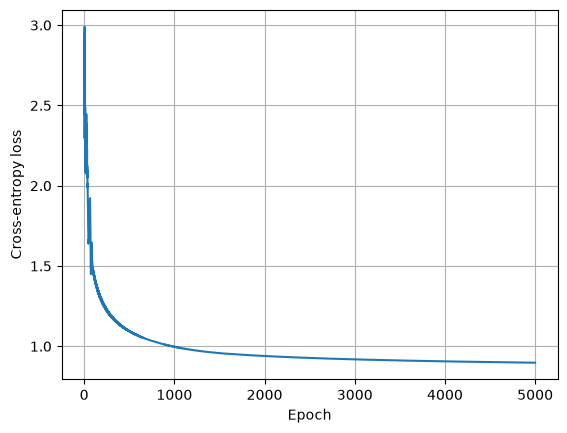

In [39]:
# execute training

W, b, losses = ut.train(X_train, y_train, learning_rate=learning_rate, epochs=epochs, lam=lam, return_losses=True)

plt.plot(losses)
plt.xlabel("Epoch")
plt.ylabel("Cross-entropy loss")
plt.grid(True)
plt.show()

# Model accuracy

In [40]:
# evaluate classifier performance

train_predictions = ut.predict(X_train, W, b)
test_predictions = ut.predict(X_test, W, b)

train_accuracy = np.mean(train_predictions == y_train)
test_accuracy = np.mean(test_predictions == y_test)

print(f"Training accuracy: {train_accuracy:.2%}")
print(f"Test accuracy: {test_accuracy:.2%}")

Training accuracy: 71.25%
Test accuracy: 71.29%


# Confusion matrix
Two types of confusion matrices are plotted here, a regular one in blue and a red one where all correct predictions (the diagonals) are set to zero, to make the errors more visible. 

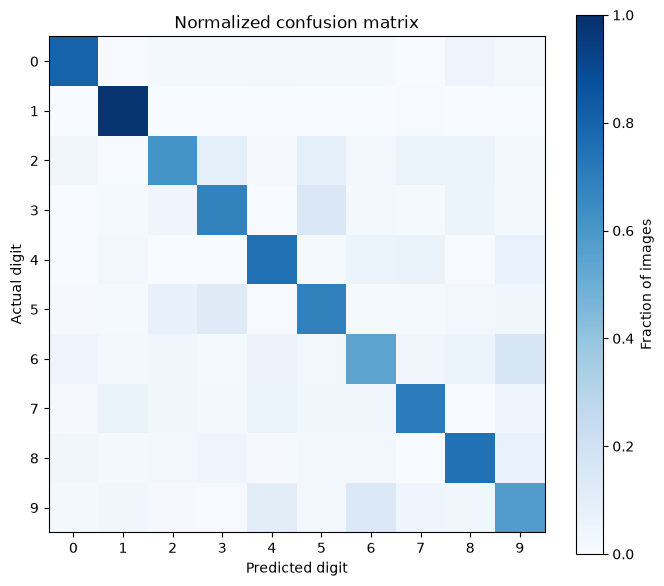

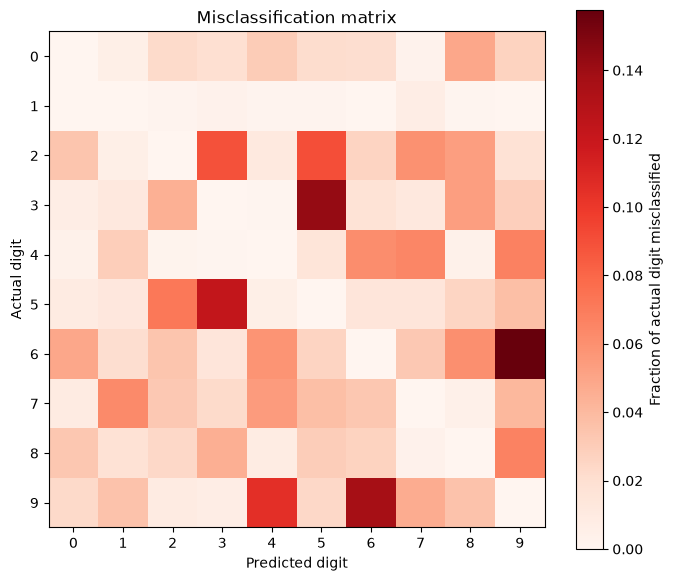

In [ ]:
# confusion matrix calculation
confusion = np.zeros((10, 10), dtype=int)

for actual, predicted in zip(y_test, test_predictions):
    confusion[actual, predicted] += 1

confusion_norm = confusion / confusion.sum(axis=1, keepdims=True)

# confusion matrix

plt.figure(figsize=(8, 7))

plt.imshow(confusion_norm, cmap="Blues", vmin=0, vmax=1)
plt.colorbar(label="Fraction of images")

plt.xticks(range(10))
plt.yticks(range(10))
plt.xlabel("Predicted digit")
plt.ylabel("Actual digit")
plt.title("Normalized confusion matrix")

plt.show()


# misclassification matrix (ie diagonals set to zero)

confusion_errors = confusion_norm.copy()
np.fill_diagonal(confusion_errors, 0)

plt.figure(figsize=(8, 7))

plt.imshow(confusion_errors, cmap="Reds")
plt.colorbar(label="Fraction of actual digit misclassified")

plt.xticks(range(10))
plt.yticks(range(10))
plt.xlabel("Predicted digit")
plt.ylabel("Actual digit")
plt.title("Misclassification matrix")

plt.show()